# 01 — Business Analysis

Python analysis of the Olist marketplace, querying the local PostgreSQL `ecommerce` database. Monetary values are in BRL (R$).

## Data Setup

In [1]:
# Connect to the local ecommerce database
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg://localhost/ecommerce")

In [2]:
# Shared chart style: dark theme and font for every chart in this notebook
import matplotlib.pyplot as plt  # pyplot = matplotlib's main charting module, nicknamed plt

# Named colour constants: change a colour here once and every chart follows
BG = "#1a1a19"          # chart background
TEXT = "#f0efec"        # titles and key labels
TEXT_MUTED = "#c3c2b7"  # axis labels, ticks and annotations
BLUE = "#3987e5"        # main series / on time
ORANGE = "#d95926"      # problem series / late

# rcParams = matplotlib's global settings; .update() changes many at once using a dictionary {"setting": value}
plt.rcParams.update({
    "figure.facecolor": BG,      # background of the whole canvas (Figure)
    "axes.facecolor": BG,        # background of the plot area (Axes)
    "savefig.facecolor": BG,     # keep the dark background when saving charts as PNG files
    "text.color": TEXT,          # default colour for titles and text
    "axes.labelcolor": TEXT_MUTED,  # x- and y-axis label colour
    "axes.edgecolor": TEXT_MUTED,   # colour of the border lines (spines)
    "xtick.color": TEXT_MUTED,   # x-axis numbers and tick marks
    "ytick.color": TEXT_MUTED,   # y-axis numbers and tick marks
    "grid.color": "#383835",     # gridline colour (subtle on dark)
    "font.family": ["Avenir Next", "Helvetica Neue", "DejaVu Sans"],  # first font found is used; the rest are fallbacks
    "font.size": 11,             # default text size
    "axes.titlesize": 14,        # title size
    "axes.titleweight": "bold",  # bold titles
    "axes.spines.top": False,    # hide the top border line
    "axes.spines.right": False,  # hide the right border line
})

## Order-Level Dataset

What does each order look like across payments, items and reviews?

CTEs collapse each table to one row per order before joining; `LEFT JOIN` keeps orders with no payment, items or review.

In [3]:
# One row per order: payments, items and reviews joined at order grain
order_query = """
WITH payments AS (
    SELECT
        order_id,
        SUM(payment_value) AS payment_value
    FROM order_payments
    GROUP BY order_id
),
items AS (
    SELECT
        order_id,
        count(*) AS item_count,
        SUM(price) AS product_value
    FROM order_items
    GROUP BY order_id
),
reviews AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM order_reviews
    GROUP BY order_id
)
SELECT
    orders.order_id,
    customers.customer_unique_id,
    customers.customer_state,
    orders.order_status,
    orders.order_purchase_timestamp,
    orders.order_delivered_customer_date,
    orders.order_estimated_delivery_date,
    payments.payment_value,
    items.item_count,
    items.product_value,
    reviews.review_score
FROM orders
JOIN customers
    ON orders.customer_id = customers.customer_id
LEFT JOIN payments
    ON orders.order_id = payments.order_id
LEFT JOIN items
    ON orders.order_id = items.order_id
LEFT JOIN reviews
    ON orders.order_id = reviews.order_id
"""

orders_df = pd.read_sql(order_query, engine)
orders_df.head()


,order_id,customer_unique_id,customer_state,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,payment_value,item_count,product_value,review_score
0,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,SP,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,259.83,1.0,239.90,4.0
1,00042b26cf59d7ce69dfabb4e55b4fd9,64b576fb70d441e8f1b2d7d446e483c5,SP,delivered,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,218.04,1.0,199.90,5.0
2,00048cc3ae777c65dbb7d2a0634bc1ea,85c835d128beae5b4ce8602c491bf385,MG,delivered,2017-05-15 21:42:34,2017-05-22 13:44:35,2017-06-06,34.59,1.0,21.90,4.0
3,0005f50442cb953dcd1d21e1fb923495,0782c41380992a5a533489063df0eef6,SP,delivered,2018-07-02 13:59:39,2018-07-04 17:28:31,2018-07-23,65.39,1.0,53.99,4.0
4,00061f2a7bc09da83e415a52dc8a4af1,107e6259485efac66428a56f10801f4f,SP,delivered,2018-03-24 22:16:10,2018-03-29 00:04:19,2018-04-09,68.87,1.0,59.99,5.0


## Delivery Performance

How early or late are orders delivered compared with the estimate?

In [4]:
# Delivery delay in days: positive = late, negative = early
delivered = orders_df["order_delivered_customer_date"]
estimated = orders_df["order_estimated_delivery_date"]

orders_df["delay_days"] = (delivered - estimated).dt.total_seconds() / 86400
orders_df["delay_days"].describe()

count    96476.000000
mean       -11.179120
std         10.186113
min       -146.016123
25%        -16.244384
50%        -11.948941
75%         -6.390000
max        188.975081
Name: delay_days, dtype: float64

In [5]:
# Delivery status, same definition as sql/analysis.sql
orders_df["delivery_status"] = "Not Delivered"
orders_df.loc[delivered.notna() & (delivered <= estimated), "delivery_status"] = "On Time"
orders_df.loc[delivered.notna() & (delivered > estimated), "delivery_status"] = "Late"

orders_df["delivery_status"].value_counts()

delivery_status
On Time          88649
Late              7827
Not Delivered     2965
Name: count, dtype: int64

### Delay Distribution

Are late orders slightly late or very late, and how early do most orders arrive?

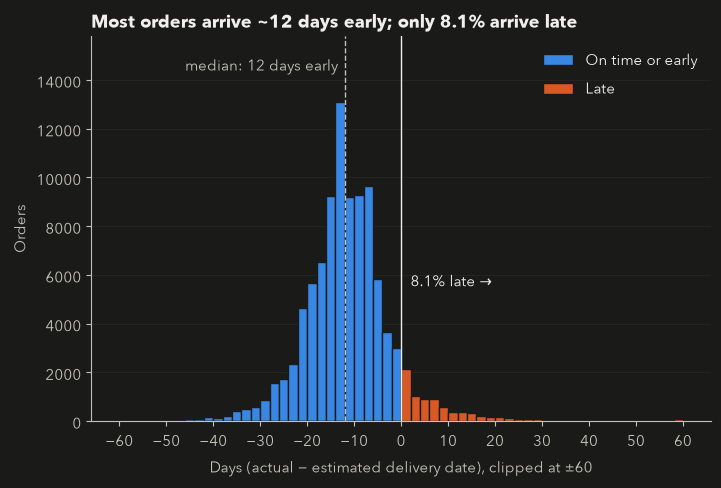

In [ ]:
# Histogram of delivery delay, delivered orders only
# 1. Keep delivered orders only and select delay_days
# .loc[row condition, column] -> one column (a Series) of the matching rows
delivered_delay = orders_df.loc[orders_df["delivery_status"] != "Not Delivered", "delay_days"]

# Key numbers for the title and annotations (calculated, not typed in)
median_delay = delivered_delay.median()
late_share = (delivered_delay > 0).mean() * 100  # mean of True/False = share that is True

# 2. Create the figure and axes
# plt.subplots() returns two objects: fig (whole canvas) and ax (the plot we draw on)
# figsize=(width, height) in inches
fig, ax = plt.subplots(figsize=(8, 5))

# 3. Draw the histogram: on time/early in blue, late in orange (shared 2-day bins so bars line up)
bins = range(-60, 62, 2)  # bin edges -60, -58, ..., 60
clipped_delay = delivered_delay.clip(-60, 60) 
# series[condition] keeps only values where the condition is True (boolean filtering)
# edgecolor = outline of each bar (matches background, so bars look separated)
# label = name shown in the legend
ax.hist(clipped_delay[delivered_delay <= 0], bins=bins, color=BLUE, edgecolor=BG, label="On time or early")
ax.hist(clipped_delay[delivered_delay > 0], bins=bins, color=ORANGE, edgecolor=BG, label="Late")

# 4. Reference lines and annotations: estimate (0 days) and median delay
# ax.get_ylim() returns (bottom, top) of the y-axis; [1] picks the top (Python counts from 0)
# raise the top by 15% so labels have empty space above the bars
ax.set_ylim(top=ax.get_ylim()[1] * 1.15)
ax.axvline(0, color=TEXT, linewidth=1)  # axvline = vertical line at x = 0 (the estimate)
ax.axvline(median_delay, color=TEXT_MUTED, linewidth=1, linestyle="--")  # "--" = dashed line
# ax.text(x, y, text): x and y are in chart units (days, orders)
# y = 95% of the axis height; ha/va = which edge of the text sits at (x, y)
# f"...{value:.0f}..." inserts a value into text; :.0f = 0 decimals, :.1f = 1 decimal; abs() drops the minus sign
ax.text(median_delay - 1.5, ax.get_ylim()[1] * 0.95, f"median: {abs(median_delay):.0f} days early",
        ha="right", va="top", color=TEXT_MUTED)
ax.text(2, ax.get_ylim()[1] * 0.35, f"{late_share:.1f}% late →", ha="left", color=TEXT)

# 5. Action title, axis labels, legend and decluttering
# loc="left" left-aligns the title like a headline
ax.set_title(f"Most orders arrive ~{abs(median_delay):.0f} days early; only {late_share:.1f}% arrive late",
             loc="left", fontsize=13)
ax.set_xlabel("Days (actual − estimated delivery date), clipped at ±60")
ax.set_ylabel("Orders")
ax.set_xticks(range(-60, 61, 10))  # x-axis label every 10 days (61 so that 60 is included)
ax.grid(axis="y", alpha=0.3)  # horizontal gridlines only; alpha = transparency (0 invisible, 1 solid)
ax.set_axisbelow(True)        # draw gridlines behind the bars
ax.legend(frameon=False)      # show the legend using each hist's label; no box around it

# 6. Show the chart
plt.show()

**Finding:** ___ *(write 1–2 sentences after looking at the chart)*